In [25]:

#0. 필요한 모듈 사용
import torch
import torch.nn as nn
import torch.optim as optim

from torchvision import datasets, transforms
from torch.utils.data import DataLoader

import matplotlib.pyplot as plt
import numpy as np

In [26]:
#1. GPU 사용 환경 준비
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(device)

cuda


In [27]:
#2. 가위바위보 데이터셋 전처리

# 기본 전처리를 위한 파이프라인
transform = transforms.Compose([
    #1) 이미지 크기를 224X224로 조정
    transforms.Resize((224,224)), 

    #2) 이미지를 Tensor로 변환(~225 -> 0~1)
    transforms.ToTensor(),

    #3) ImageNet 기준 채널별 표준화(빨강,초록, 파랑)
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

In [28]:
#3. 가위바위보 이미지 데이터 위치, 폴더 확인하기
import os

print("현재 작업 위치:", os.getcwd())
print("현재 작업 폴더:", os.listdir("."))

현재 작업 위치: c:\Users\mbc\Desktop\엄정희 가위바위보
현재 작업 폴더: ['.git', 'rps', 'rps-test-set', '가위바위보.ipynb']


In [29]:
#4. 데이터 구조 확인하기
import os
print("학습폴더:", os.listdir('rps'))
print("데아터폴더", os.listdir("rps-test-set"))


학습폴더: ['paper', 'rock', 'scissors']
데아터폴더 ['paper', 'rock', 'scissors']


In [30]:
#5. PyTorch 데이터셋 생성
# 이미지 데이터셋 불러오기
train_full_dataset = datasets.ImageFolder(
    root= "rps",
    transform=transform
)

test_dataset = datasets.ImageFolder(
    root= "rps-test-set",
    transform= transform
)

print("전체 학습 데이터", len(train_full_dataset))
print("테스트 데이터", len(test_dataset))
print("클래스", train_full_dataset.classes)
print("클래스 번호", train_full_dataset.class_to_idx)

전체 학습 데이터 2520
테스트 데이터 372
클래스 ['paper', 'rock', 'scissors']
클래스 번호 {'paper': 0, 'rock': 1, 'scissors': 2}


In [31]:
# 학습데이터와 검증 데이터 분리
#기존 학습이미지 2,520장을 80:20
from torch.utils.data import random_split

train_size = int(len(train_full_dataset) * 0.8)
val_size = len(train_full_dataset) - train_size

train_dataset, val_dataset = random_split(
    train_full_dataset,
    [train_size, val_size],
    generator= torch.Generator().manual_seed(42)

)
print("학습 데이터",len(train_dataset))
print("검증 데이터",len(val_dataset))
print("테스트 데이터", len(test_dataset))

학습 데이터 2016
검증 데이터 504
테스트 데이터 372


In [32]:
#5. DataLoader 생성(이미지 여러장을 묶어서 학습)

train_loader = DataLoader(
    train_dataset,
    batch_size=32,
    shuffle=True
)
val_loader = DataLoader(
    val_dataset,
    batch_size=32,
    shuffle=False
)

In [33]:
#6. CNN 모델 라이브러리 준비

# torchvision에서 사전학습된 CNN 모델을 불러오기 위한 모듈
from torchvision import models

In [34]:
# 7. ResNet50 사전학습 가중치 선택

# ImageNet 데이터로 미리 학습된 ResNet50 가중치 사용
weights = models.ResNet50_Weights.IMAGENET1K_V2

In [35]:
# 사전학습 가중치 확인하기
print(weights)

ResNet50_Weights.IMAGENET1K_V2


In [36]:
# 8. ResNet50 사전학습 모델 불러오기

# 앞에서 선택한 ImageNet 사전학습 가중치를 적용하여 모델 생성
model = models.resnet50(weights=weights)

# 모델이 정상적으로 생성되었는지 확인
print(type(model))


<class 'torchvision.models.resnet.ResNet'>


In [37]:
# 9. ResNet50 모델의 마지막 분류층 확인

# fc(Fully Connected): CNN이 추출한 특징을 최종 분류하는 중
print(model.fc)

Linear(in_features=2048, out_features=1000, bias=True)


In [38]:
#10. ResNet50의 마지막 분류층 변경

# 기존 2048개의 특징값은 그대로 사용하고,
# 출력 클래스를 1000개에서 3개(가위, 바위, 보)로 변경
model.fc = nn.Linear(model.fc.in_features, 3)

#변경된 분류층 확인
print(model.fc)

Linear(in_features=2048, out_features=3, bias=True)


In [39]:
# 11. CNN 특징 추출층 고정(Freeze) = 새로운 fc 분류층 학습

# ImageNet에서 사전학습된 기준 CNN의 가중치를 고정
for param in model.parameters():
    param.requires_grad = False

# 가위, 바위, 보를 분류할 마지막 fc층만 학습 가능하게 설정
for param in model.fc.parameters():
    param.requires_grad = True

# 학습 가능한 파라미터수 확인
trainable = sum(p.numel() for p in model.parameters( ) if p.requires_grad)
print("학습 가능한 파라미터 수:", trainable)

학습 가능한 파라미터 수: 6147


In [40]:
# 현재 사용 중인 GPU 이름 확인
print(torch.cuda.get_device_name(0))

NVIDIA GeForce RTX 3060 Ti


In [41]:
# 13. 손실 함수와 옵티마이저 설정
# ResNet50이 가위,바위,보를 학습할 수 있도록 준비
import torch.optim as optim
#1. 예측값과 실제 정답의 차이를 계산하는 손실 함수
criterion = nn.CrossEntropyLoss()

#2. 손실을 줄이도록 학습 가능한 가중치를 수정하는 옵티마이저
optimizer = optim.Adam(
    model.fc.parameters(),
    lr=0.001
)

print("손실 함수:", criterion)
print("옵티마이저:", optimizer.__class__.__name__)

손실 함수: CrossEntropyLoss()
옵티마이저: Adam


In [47]:
# 14번 모델 검증이 되지 않아 ResNet50을 cpu->GPU
# ResNet50 모델을 GPU로 이동 

# 학습 시작 전 모델과 데이터의 장치 통일
model = model.to(device)

# 모델과 GPU 연결 확인
print("모델 위치:", next(model.parameters()).device)
print("사용 장치:", device)

모델 위치: cuda:0
사용 장치: cuda


In [48]:
# 14. ResNet50 CNN 모델 학습 및 검증

epochs = 5  # 전체 학습 데이터를 5번 반복 학습

for epoch in range(epochs):

    # ==========================
    # 1. 학습(Training)
    # ==========================
    model.eval()  # 고정된 ResNet50의 BatchNorm 통계 유지
    model.fc.train()  # 마지막 분류층 학습

    train_loss = 0.0
    train_correct = 0
    train_total = 0

    for images, labels in train_loader:

        # 이미지와 정답을 GPU로 이동
        images = images.to(device)
        labels = labels.to(device)

        # 이전 기울기 초기화
        optimizer.zero_grad()

        # 예측 → 손실 계산 → 역전파 → 가중치 수정
        outputs = model(images)
        loss = criterion(outputs, labels)
        loss.backward()
        optimizer.step()

        # 손실 및 정확도 계산
        train_loss += loss.item() * images.size(0)
        predictions = outputs.argmax(dim=1)

        train_correct += (predictions == labels).sum().item()
        train_total += labels.size(0)

    # ==========================
    # 2. 검증(Validation)
    # ==========================
    model.eval()

    val_correct = 0
    val_total = 0

    with torch.no_grad():
        for images, labels in val_loader:

            images = images.to(device)
            labels = labels.to(device)

            outputs = model(images)
            predictions = outputs.argmax(dim=1)

            val_correct += (predictions == labels).sum().item()
            val_total += labels.size(0)

    # ==========================
    # 3. 결과 출력
    # ==========================
    train_acc = 100 * train_correct / train_total
    val_acc = 100 * val_correct / val_total
    avg_loss = train_loss / train_total

    print(
        f"Epoch [{epoch+1}/{epochs}] "
        f"Loss: {avg_loss:.4f} | "
        f"Train Acc: {train_acc:.2f}% | "
        f"Val Acc: {val_acc:.2f}%"
    )

Epoch [1/5] Loss: 0.6409 | Train Acc: 86.56% | Val Acc: 98.61%
Epoch [2/5] Loss: 0.2588 | Train Acc: 99.16% | Val Acc: 100.00%
Epoch [3/5] Loss: 0.1526 | Train Acc: 99.70% | Val Acc: 100.00%
Epoch [4/5] Loss: 0.1046 | Train Acc: 100.00% | Val Acc: 100.00%
Epoch [5/5] Loss: 0.0774 | Train Acc: 100.00% | Val Acc: 100.00%


In [51]:
# 테스트 데이터셋이 만들어져 있는지 확인
print(len(test_dataset))

# 15번 테스트 데이터를 평가하기 전 테스트 로더를 만들지 않고 실행 생성하기
from torch.utils.data import DataLoader

test_loader = DataLoader(
    test_dataset,
    batch_size=32,
    shuffle=False
)

print("테스트 이미지 수:", len(test_dataset))
print("테스트 배치 수:", len(test_loader))


372
테스트 이미지 수: 372
테스트 배치 수: 12


In [52]:
# 15. 테스트 데이터로 CNN 모델 성능 평가

model.eval()  # 모델을 평가 모드로 변경

test_correct = 0
test_total = 0

with torch.no_grad():  # 평가할 때는 가중치를 학습하지 않음
    for images, labels in test_loader:

        images = images.to(device)
        labels = labels.to(device)

        outputs = model(images)
        predictions = outputs.argmax(dim=1)

        test_correct += (predictions == labels).sum().item()
        test_total += labels.size(0)

test_acc = 100 * test_correct / test_total

print(f"테스트 정확도: {test_acc:.2f}%")
print(f"정답 개수: {test_correct}/{test_total}")

테스트 정확도: 79.30%
정답 개수: 295/372


In [ ]:
# 16. 테스트 이미지 불러오기
from torchvision import datasets

test_dataset = datasets.ImageFolder(
    root="rps-test-set",
    transform=transform
)

In [53]:
# 17. 클래스별 테스트 정확도 확인 - 어떤 손동작을 가장 많이 틀렸는지 확인하기

model.eval()

class_correct = [0, 0, 0]
class_total = [0, 0, 0]

with torch.no_grad():
    for images, labels in test_loader:
        images = images.to(device)
        labels = labels.to(device)

        outputs = model(images)
        predictions = outputs.argmax(dim=1)

        for label, prediction in zip(labels, predictions):
            idx = label.item()
            class_total[idx] += 1

            if label == prediction:
                class_correct[idx] += 1

# 클래스별 정확도 출력
for i, class_name in enumerate(test_dataset.classes):
    accuracy = 100 * class_correct[i] / class_total[i]
    print(f"{class_name}: {accuracy:.2f}% "
          f"({class_correct[i]}/{class_total[i]})")

paper: 42.74% (53/124)
rock: 100.00% (124/124)
scissors: 95.16% (118/124)


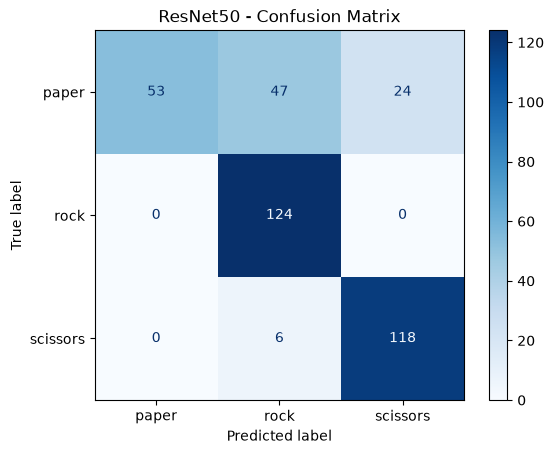

In [54]:
# 18. 혼동행렬로 오분류 확인

from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

model.eval()

y_true = []  # 실제 정답
y_pred = []  # 모델 예측

with torch.no_grad():
    for images, labels in test_loader:
        images = images.to(device)

        outputs = model(images)
        predictions = outputs.argmax(dim=1)

        y_true.extend(labels.tolist())
        y_pred.extend(predictions.cpu().tolist())

# 혼동행렬 계산
cm = confusion_matrix(y_true, y_pred, labels=[0, 1, 2])

# 시각화
disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=test_dataset.classes
)

disp.plot(cmap="Blues")
plt.title("ResNet50 - Confusion Matrix")
plt.show()

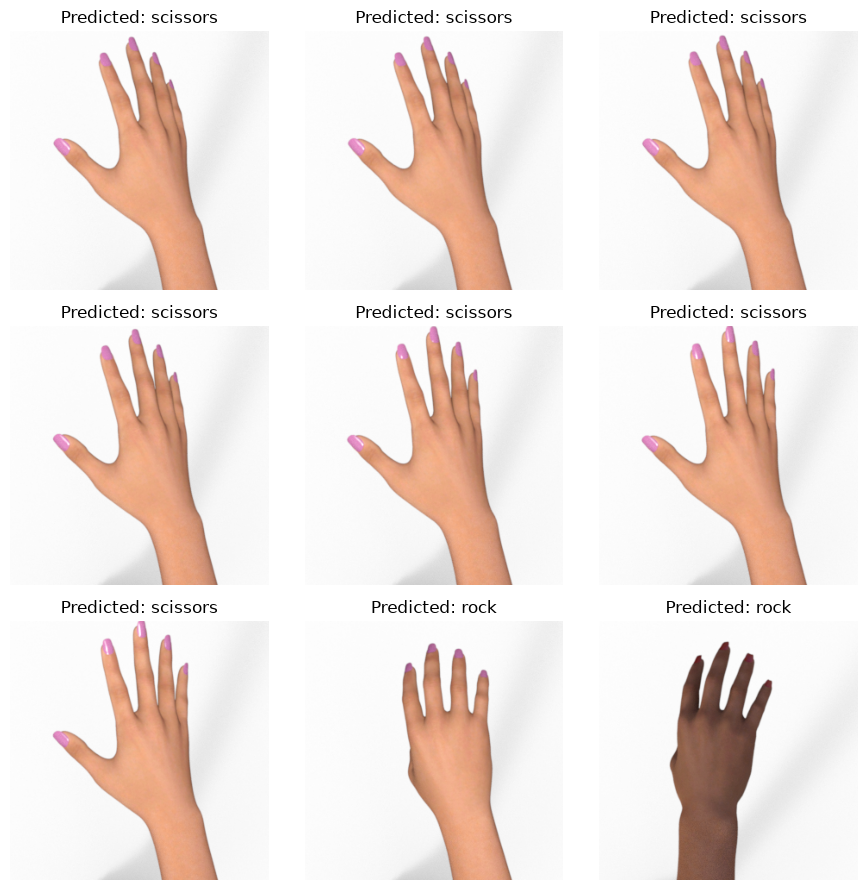

In [55]:
# 19. 잘못 예측한 보 이미지 확인

from PIL import Image
import matplotlib.pyplot as plt

model.eval()

wrong_paper = []

for path, label in test_dataset.samples:
    if test_dataset.classes[label] != "paper":
        continue

    image = Image.open(path).convert("RGB")
    tensor = transform(image).unsqueeze(0).to(device)

    with torch.no_grad():
        output = model(tensor)
        pred = output.argmax(dim=1).item()

    if pred != label:
        wrong_paper.append((image, test_dataset.classes[pred]))

# 오분류된 보 이미지 9장 확인
n = min(9, len(wrong_paper))

fig, axes = plt.subplots(3, 3, figsize=(9, 9))

for ax in axes.flat:
    ax.axis("off")

for i in range(n):
    image, predicted = wrong_paper[i]
    axes.flat[i].imshow(image)
    axes.flat[i].set_title(f"Predicted: {predicted}")

plt.tight_layout()
plt.show()

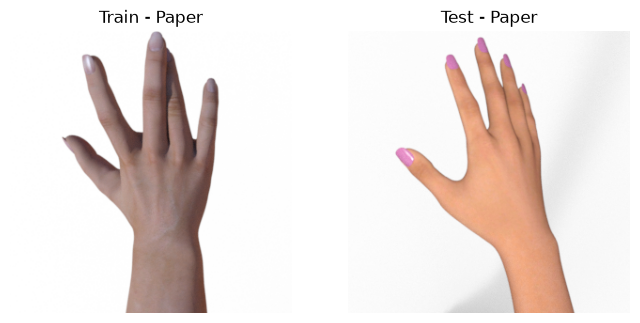

In [56]:
# 20. 학습용 보 이미지와 테스트용 보 이미지 비교

from PIL import Image
import matplotlib.pyplot as plt

train_path = train_full_dataset.samples[
    next(i for i, (_, label) in enumerate(train_full_dataset.samples)
         if train_full_dataset.classes[label] == "paper")
][0]

test_path = test_dataset.samples[
    next(i for i, (_, label) in enumerate(test_dataset.samples)
         if test_dataset.classes[label] == "paper")
][0]

fig, axes = plt.subplots(1, 2, figsize=(8, 4))

axes[0].imshow(Image.open(train_path))
axes[0].set_title("Train - Paper")

axes[1].imshow(Image.open(test_path))
axes[1].set_title("Test - Paper")

for ax in axes:
    ax.axis("off")

plt.show()

In [59]:
# 21. 학습 데이터 증강 설정 => 학습 데이터 전용 train_transform 새롭게 만들기

train_transform = transforms.Compose([
    # 이미지 크기 조정
    transforms.Resize((224, 224)),

    # 손 방향을 조금씩 회전
    transforms.RandomRotation(degrees=15),

    # 이미지 밝기와 대비 변화
    transforms.ColorJitter(
        brightness=0.2,
        contrast=0.2
    ),

    # 이미지를 Tensor로 변환
    transforms.ToTensor(),

    # ImageNet 기준 RGB 채널별 정규화
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])


In [60]:
# 22. 학습 데이터에만 데이터 증강 적용
# 기존 학습 2,016장/ 검증 504장 분할 유지

from torch.utils.data import Subset

# 기존 학습·검증 데이터의 인덱스 유지
train_indices = train_dataset.indices
val_indices = val_dataset.indices

# 학습용: 데이터 증강 적용
augmented_dataset = datasets.ImageFolder(
    root="rps",
    transform=train_transform
)

# 검증용: 기존 전처리만 적용 (증강 X)
validation_dataset = datasets.ImageFolder(
    root="rps",
    transform=transform
)

# 기존 분할 인덱스를 사용해 데이터셋 재구성
train_dataset = Subset(augmented_dataset, train_indices)
val_dataset = Subset(validation_dataset, val_indices)

print("학습 이미지:", len(train_dataset))
print("검증 이미지:", len(val_dataset))

학습 이미지: 2016
검증 이미지: 504


In [61]:
# 23. 데이터 증강 적용 후 DataLoader 재생성

from torch.utils.data import DataLoader

# 1. 학습용 DataLoader (데이터 증강 O)
train_loader = DataLoader(
    train_dataset,
    batch_size=32,
    shuffle=True
)

# 2. 검증용 DataLoader (데이터 증강 X)
val_loader = DataLoader(
    val_dataset,
    batch_size=32,
    shuffle=False
)

# 3. 테스트용 DataLoader (데이터 증강 X)
test_loader = DataLoader(
    test_dataset,
    batch_size=32,
    shuffle=False
)

# 배치 개수 확인
print("Train:", len(train_loader))
print("Validation:", len(val_loader))
print("Test:", len(test_loader))

Train: 63
Validation: 16
Test: 12


In [62]:
# 24. 데이터 증강 실험용 ResNet50 모델 생성

# 실험 결과의 재현성을 높이기 위한 시드 설정
torch.manual_seed(42)
torch.cuda.manual_seed_all(42)

# 동일한 ImageNet 사전학습 모델 불러오기
model_aug = models.resnet50(weights=weights)

# 기존 특징 추출층 고정
for param in model_aug.parameters():
    param.requires_grad = False

# 마지막 분류층을 3개로 변경
model_aug.fc = nn.Linear(model_aug.fc.in_features, 3)

# GPU로 이동
model_aug = model_aug.to(device)

print(model_aug.fc)
print("모델 위치:", next(model_aug.parameters()).device)

Linear(in_features=2048, out_features=3, bias=True)
모델 위치: cuda:0


In [63]:
# 25. 데이터 증강 모델의 손실 함수 및 옵티마이저 설정

# 예측값과 실제 정답의 차이를 계산
criterion_aug = nn.CrossEntropyLoss()

# 손실을 줄이도록 마지막 분류층의 가중치를 수정
optimizer_aug = optim.Adam(
    model_aug.fc.parameters(),
    lr=0.001
)

print("손실 함수:", criterion_aug)
print("옵티마이저:", optimizer_aug.__class__.__name__)

손실 함수: CrossEntropyLoss()
옵티마이저: Adam


In [64]:
# 26. 데이터 증강 ResNet50 모델 학습 (5 Epoch)

epochs = 5

# Epoch별 결과 저장
train_losses_aug = []
train_accs_aug = []
val_accs_aug = []

for epoch in range(epochs):

    # 1. 학습
    model_aug.eval()  # 고정된 CNN의 BatchNorm 통계 유지
    model_aug.fc.train()

    train_loss = 0.0
    train_correct = 0
    train_total = 0

    for images, labels in train_loader:

        # 이미지와 정답을 GPU로 이동
        images = images.to(device)
        labels = labels.to(device)

        # 이전 기울기 초기화
        optimizer_aug.zero_grad()

        # 예측 → 손실 계산 → 역전파 → 가중치 수정
        outputs = model_aug(images)
        loss = criterion_aug(outputs, labels)

        loss.backward()
        optimizer_aug.step()

        # 학습 손실 및 정확도 계산
        train_loss += loss.item() * images.size(0)
        predictions = outputs.argmax(dim=1)

        train_correct += (predictions == labels).sum().item()
        train_total += labels.size(0)

    # 2. 검증
    model_aug.eval()

    val_correct = 0
    val_total = 0

    with torch.no_grad():
        for images, labels in val_loader:

            images = images.to(device)
            labels = labels.to(device)

            outputs = model_aug(images)
            predictions = outputs.argmax(dim=1)

            val_correct += (predictions == labels).sum().item()
            val_total += labels.size(0)

    # 3. Epoch별 결과 계산
    avg_loss = train_loss / train_total
    train_acc = 100 * train_correct / train_total
    val_acc = 100 * val_correct / val_total

    # 결과 저장
    train_losses_aug.append(avg_loss)
    train_accs_aug.append(train_acc)
    val_accs_aug.append(val_acc)

    print(
        f"Epoch [{epoch+1}/{epochs}] | "
        f"Loss: {avg_loss:.4f} | "
        f"Train Acc: {train_acc:.2f}% | "
        f"Val Acc: {val_acc:.2f}%"
    )

Epoch [1/5] | Loss: 0.6372 | Train Acc: 84.33% | Val Acc: 96.43%
Epoch [2/5] | Loss: 0.2813 | Train Acc: 97.52% | Val Acc: 96.83%
Epoch [3/5] | Loss: 0.1858 | Train Acc: 98.46% | Val Acc: 97.62%
Epoch [4/5] | Loss: 0.1425 | Train Acc: 98.96% | Val Acc: 98.41%
Epoch [5/5] | Loss: 0.1084 | Train Acc: 99.21% | Val Acc: 97.62%


In [65]:
# 27. 데이터 증강 모델 테스트 평가

# 학습이 끝난 모델을 평가 모드로 변경
model_aug.eval()

test_correct_aug = 0
test_total_aug = 0

with torch.no_grad():
    for images, labels in test_loader:

        # 이미지와 정답을 GPU로 이동
        images = images.to(device)
        labels = labels.to(device)

        # 모델 예측
        outputs = model_aug(images)
        predictions = outputs.argmax(dim=1)

        # 정답 개수 계산
        test_correct_aug += (predictions == labels).sum().item()
        test_total_aug += labels.size(0)

# 전체 테스트 정확도
test_acc_aug = 100 * test_correct_aug / test_total_aug

print(f"기존 모델 정확도: {test_acc:.2f}%")
print(f"증강 모델 정확도: {test_acc_aug:.2f}%")
print(f"정답 개수: {test_correct_aug}/{test_total_aug}")

기존 모델 정확도: 79.30%
증강 모델 정확도: 74.73%
정답 개수: 278/372


In [66]:
# 28. 증강 모델의 가위·바위·보 정확도 확인

model_aug.eval()

class_correct_aug = [0, 0, 0]
class_total_aug = [0, 0, 0]

with torch.no_grad():
    for images, labels in test_loader:
        images = images.to(device)
        labels = labels.to(device)

        outputs = model_aug(images)
        predictions = outputs.argmax(dim=1)

        for label, pred in zip(labels, predictions):
            idx = label.item()
            class_total_aug[idx] += 1

            if label == pred:
                class_correct_aug[idx] += 1

for i, name in enumerate(test_dataset.classes):
    acc = 100 * class_correct_aug[i] / class_total_aug[i]
    print(f"{name}: {acc:.2f}% "
          f"({class_correct_aug[i]}/{class_total_aug[i]})")

paper: 37.10% (46/124)
rock: 100.00% (124/124)
scissors: 87.10% (108/124)


In [ ]:
# 세번째  테스트 - ResNet50의 일부 특징 추출층을 미세조정(Fine-tuning)
# 29. Fine-tuning용 ResNet50 모델 생성

torch.manual_seed(42)
torch.cuda.manual_seed_all(42)

# 사전학습된 ResNet50 불러오기
model_ft = models.resnet50(weights=weights)

# 1. 기존 CNN 전체 가중치 고정
for param in model_ft.parameters():
    param.requires_grad = False

# 2. 마지막 특징 추출 블록(layer4) 학습 허용
for param in model_ft.layer4.parameters():
    param.requires_grad = True

# 3. 마지막 분류층을 가위·바위·보 3개로 변경
model_ft.fc = nn.Linear(model_ft.fc.in_features, 3)

# 4. GPU로 이동
model_ft = model_ft.to(device)

print("분류층:", model_ft.fc)
print("실행 장치:", next(model_ft.parameters()).device)

분류층: Linear(in_features=2048, out_features=3, bias=True)
실행 장치: cuda:0
